# Diagnóstico Automático de Eletrocardiogramas com Transformers
## Notebook 02 - Modelagem, Treinamento e Avaliação

**Projeto da Disciplina em Grupo - Inteligência Artificial (7º CC, Turma 7N) - Parte 3 (N2)**
Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática
Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira

Integrantes:
- Enzo Ponte Gamberi - RA 10389931 - 10389931@mackenzista.com.br
- João Guilherme Messias de Oliveira Santos - RA 10426110 - 10426110@mackenzista.com.br
- Luís Henrique Ribeiro Fernandes - RA 10420079 - 10420079@mackenzista.com.br

---

**Síntese do conteúdo do arquivo:** treina e avalia o classificador de batimentos baseado em
Transformer (arquitetura em `src/modelo.py`) no protocolo inter-paciente DS1/DS2. Compara o modelo
com um baseline de Random Forest, mede a contribuição de cada componente (ablações), repete o
experimento no protocolo intra-paciente para mostrar o quanto ele infla os resultados, analisa os
erros por paciente e mostra mapas de atenção do modelo. Salva o modelo treinado em `modelos/` e as
métricas e figuras em `resultados/`.

**Histórico de alterações:**
- 2026-11-19, João Guilherme: criação do notebook (N2): baseline, Transformer com 5 sementes,
  ablações, experimento intra-paciente, análise de erros por registro e mapas de atenção.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split

sys.path.insert(0, str(Path('..') / 'src'))
import ecg_utils as eu
import modelo as m

PROC = Path('../dataset/processed')
RES = Path('../resultados'); RES.mkdir(exist_ok=True)
MOD = Path('../modelos'); MOD.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

DISP = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '| dispositivo:', DISP,
      torch.cuda.get_device_name(0) if DISP == 'cuda' else '')

PyTorch 2.6.0+cu124 | dispositivo: cuda NVIDIA GeForce RTX 4060


In [2]:
# Conjunto gerado pelo notebook 01 (se não existir, rode o notebook 01 antes)
d = np.load(PROC / 'mitdb_ds1_ds2.npz')
X1, R1, y1, o1 = d['X1'], d['R1'], d['y1'], d['o1']
X2, R2, y2, o2 = d['X2'], d['R2'], d['y2'], d['o2']
print('treino (DS1):', X1.shape, np.bincount(y1))
print('teste  (DS2):', X2.shape, np.bincount(y2))

treino (DS1): (50994, 2, 256) [45848   944  3788   414]
teste  (DS2): (49685, 2, 256) [44240  1837  3220   388]


## 1. Protocolo de avaliação

- **Treino:** DS1 (22 pacientes). Do DS1 separamos 15% dos batimentos, estratificados por classe,
  para validação. A validação só escolhe a época com maior F1-macro (early stopping).
- **Teste:** DS2 (22 outros pacientes), usado uma única vez por modelo treinado, sem ajuste nenhum.

A validação é uma amostra aleatória dos mesmos pacientes do treino, e isso tem um custo: ela é
otimista e não avisa quando o modelo começa a decorar pacientes. Uma validação por paciente seria o
ideal, mas não funciona nesta base: 90% dos batimentos F do DS1 estão no registro 208. Separar esse
paciente para validação deixaria o treino quase sem exemplos de F.

**Métricas** (as mesmas da norma AAMI EC57 e de de Chazal et al., 2004): sensibilidade (Se, que é o
recall), valor preditivo positivo (VPP, que é a precisão) e F1 de cada classe, além do F1-macro e da
acurácia. O F1-macro é a métrica principal, porque dá o mesmo peso às quatro classes. A acurácia
aparece por completude: com 89% de batimentos N, um modelo que responde "N" para tudo já chega a 89%.

In [3]:
def metricas(y, p):
    res = {'acuracia': (y == p).mean(), 'f1_macro': f1_score(y, p, average='macro')}
    se = recall_score(y, p, average=None, labels=range(4), zero_division=0)
    vpp = precision_score(y, p, average=None, labels=range(4), zero_division=0)
    f1 = f1_score(y, p, average=None, labels=range(4), zero_division=0)
    for i, c in enumerate(eu.CLASSES):
        res[f'Se_{c}'], res[f'VPP_{c}'], res[f'F1_{c}'] = se[i], vpp[i], f1[i]
    return res

i_tr, i_va = train_test_split(np.arange(len(y1)), test_size=0.15, stratify=y1, random_state=42)
treino = (X1[i_tr], R1[i_tr], y1[i_tr])
valid = (X1[i_va], R1[i_va], y1[i_va])
print('treino:', len(i_tr), ' validação:', len(i_va))
print('pesos de classe na perda:', dict(zip(eu.CLASSES, m.pesos_classe(y1[i_tr]).numpy().round(2))))

treino: 43344  validação: 7650
pesos de classe na perda: {'N': np.float32(0.18), 'S': np.float32(1.27), 'V': np.float32(0.63), 'F': np.float32(1.92)}


## 2. Baseline: Random Forest

Antes do Transformer, um modelo clássico de aprendizado de máquina serve de referência. O Random
Forest recebe os 5 atributos de ritmo e os dois canais do batimento subamostrados de 8 em 8 (32
pontos cada, 69 atributos ao todo), com pesos de classe balanceados. Se o Transformer não superar
esse baseline, a complexidade extra não se justifica.

In [4]:
def atributos_rf(X, R):
    return np.hstack([R, X[:, 0, ::8], X[:, 1, ::8]])

t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                            n_jobs=-1, random_state=42)
rf.fit(atributos_rf(X1, R1), y1)
p_rf = rf.predict(atributos_rf(X2, R2))
print(f'tempo: {time.time() - t0:.0f} s')
res_rf = metricas(y2, p_rf)
pd.Series(res_rf).round(3).to_frame('Random Forest').T

tempo: 18 s


,acuracia,f1_macro,Se_N,VPP_N,F1_N,Se_S,VPP_S,F1_S,Se_V,VPP_V,F1_V,Se_F,VPP_F,F1_F
Random Forest,0.946,0.522,0.991,0.952,0.971,0.115,0.394,0.179,0.922,0.957,0.939,0.0,0.0,0.0


## 3. Transformer

O batimento (2 canais × 256 amostras) é cortado em 31 trechos ("patches") de 16 amostras com passo
de 8, por uma convolução 1D. Cada patch vira um token de dimensão 64. Um token `[CLS]` aprendível
entra no início da sequência, e somamos a todos um embedding posicional aprendível. Três camadas de
encoder Transformer (4 cabeças de atenção, rede feed-forward de 128 unidades, pré-normalização)
processam a sequência. A saída do `[CLS]` é concatenada a um embedding de 32 dimensões dos atributos
RR, e uma pequena rede densa produz as 4 probabilidades.

Escolhas de treino: perda de entropia cruzada com peso de cada classe proporcional à raiz do inverso
da frequência (o peso inverso puro fazia o modelo marcar F em excesso), AdamW (lr 1e-3, weight decay
1e-2) com decaimento cosseno, 15 épocas, lotes de 256, e aumento de dados leve (escala de amplitude,
ruído gaussiano e deslocamento de até 5 amostras). Para medir a variação entre execuções, o
treinamento é repetido com 5 sementes.

In [5]:
modelo_teste = m.ECGTransformer()
print(modelo_teste)
print('parâmetros treináveis:', sum(p.numel() for p in modelo_teste.parameters() if p.requires_grad))

ECGTransformer(
  (embed): Conv1d(2, 64, kernel_size=(16,), stride=(8,))
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (rr_mlp): Sequential(
    (0): Linear(in_features=5, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=32, out_features=32,

C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


In [6]:
def rodar(sementes, rotulo, kw_modelo=None, kw_treino=None, dados_treino=None, dados_valid=None,
          dados_teste=None, guardar=False):
    kw_modelo, kw_treino = kw_modelo or {}, kw_treino or {}
    dtr, dva = dados_treino or treino, dados_valid or valid
    Xt, Rt, yt = dados_teste or (X2, R2, y2)
    linhas, extras = [], {}
    for s in sementes:
        torch.manual_seed(s)
        t0 = time.time()
        mod = m.ECGTransformer(**kw_modelo)
        mod, hist = m.treinar(mod, dtr, dva, DISP, epocas=15, semente=s, verbose=False, **kw_treino)
        prob = m.prever(mod, Xt, Rt, DISP)
        r = metricas(yt, prob.argmax(1)); r.update(semente=s, config=rotulo, tempo_s=time.time() - t0)
        linhas.append(r)
        print(f'{rotulo:28s} semente {s}: F1-macro={r["f1_macro"]:.3f}  acurácia={r["acuracia"]:.3f}  '
              f'({r["tempo_s"]:.0f} s)')
        if guardar and s == sementes[0]:
            extras = {'modelo': mod, 'hist': hist, 'prob': prob}
    return pd.DataFrame(linhas), extras

SEMENTES = [0, 1, 2, 3, 4]
df_tf, principal = rodar(SEMENTES, 'Transformer (completo)', guardar=True)

Transformer (completo)       semente 0: F1-macro=0.520  acurácia=0.922  (45 s)


C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Transformer (completo)       semente 1: F1-macro=0.554  acurácia=0.942  (45 s)


C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Transformer (completo)       semente 2: F1-macro=0.546  acurácia=0.937  (44 s)


C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Transformer (completo)       semente 3: F1-macro=0.524  acurácia=0.928  (46 s)


C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Transformer (completo)       semente 4: F1-macro=0.519  acurácia=0.914  (48 s)


In [7]:
cols = ['acuracia', 'f1_macro'] + [f'{k}_{c}' for c in eu.CLASSES for k in ['Se', 'VPP', 'F1']]
resumo_tf = df_tf[cols].agg(['mean', 'std']).T.round(3)
resumo_tf.columns = ['média (5 sementes)', 'desvio padrão']
resumo_tf

,média (5 sementes),desvio padrão
acuracia,0.929,0.011
f1_macro,0.533,0.017
Se_N,0.965,0.011
VPP_N,0.960,0.003
F1_N,0.962,0.007
Se_S,0.204,0.038
VPP_S,0.318,0.085
F1_S,0.248,0.053
Se_V,0.948,0.026
VPP_V,0.866,0.035


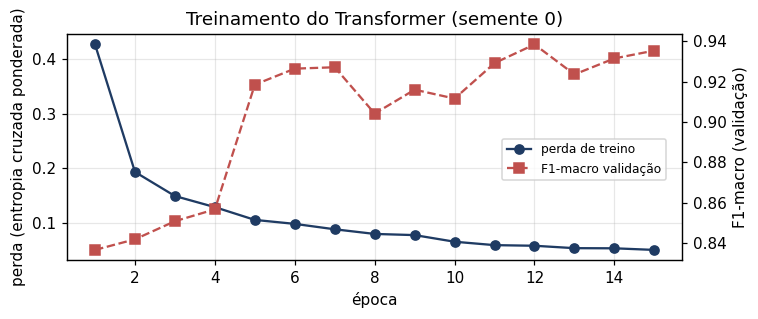

modelo salvo em ..\modelos\ecg_transformer.pt


In [8]:
# Curva de treino da semente 0 e salvamento do modelo usado na demonstração
hist = pd.DataFrame(principal['hist'])
fig, ax1 = plt.subplots(figsize=(7, 3))
ax1.plot(hist.epoca, hist.perda_treino, 'o-', color='#1f3b63', label='perda de treino')
ax1.set_xlabel('época'); ax1.set_ylabel('perda (entropia cruzada ponderada)')
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(hist.epoca, hist.f1_macro_valid, 's--', color='#c0504d', label='F1-macro validação')
ax2.set_ylabel('F1-macro (validação)')
fig.legend(loc='center right', bbox_to_anchor=(0.88, 0.5), fontsize=8)
plt.title('Treinamento do Transformer (semente 0)')
plt.tight_layout(); plt.savefig(RES / 'curva_treino.png', bbox_inches='tight'); plt.show()

torch.save({'estado': principal['modelo'].state_dict(), 'config': {}, 'classes': eu.CLASSES},
           MOD / 'ecg_transformer.pt')
print('modelo salvo em', MOD / 'ecg_transformer.pt')

## 4. Ablações: o que cada componente acrescenta

Cada variante tira uma peça do modelo completo e é treinada com 3 sementes:

- **sem atributos RR:** só a forma de onda (os dois canais);
- **sem canal relativo:** um canal só, sem a diferença em relação ao molde do paciente (é a entrada
  usada nos primeiros testes do grupo);
- **sem peso de classe:** entropia cruzada comum.

In [9]:
ablacoes = [
    ('sem atributos RR', dict(usar_rr=False), {}),
    ('sem canal relativo', dict(n_canais=1), {}),
    ('sem peso de classe', {}, dict(potencia_peso=0.0)),
]
dfs = [df_tf]
for rot, kwm, kwt in ablacoes:
    dfa, _ = rodar(SEMENTES[:3], rot, kwm, kwt)
    dfs.append(dfa)
df_abl = pd.concat(dfs)

C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


sem atributos RR             semente 0: F1-macro=0.502  acurácia=0.932  (43 s)


C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


sem atributos RR             semente 1: F1-macro=0.486  acurácia=0.915  (44 s)


C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


sem atributos RR             semente 2: F1-macro=0.479  acurácia=0.884  (46 s)


... (8 outputs left out)

C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


sem peso de classe           semente 1: F1-macro=0.530  acurácia=0.938  (48 s)


C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


sem peso de classe           semente 2: F1-macro=0.506  acurácia=0.939  (50 s)


In [10]:
def media_dp(df, col):
    g = df.groupby('config', sort=False)[col]
    return g.mean().map('{:.3f}'.format) + ' ± ' + g.std().map('{:.3f}'.format)

tab_abl = pd.DataFrame({c: media_dp(df_abl, c) for c in ['f1_macro', 'acuracia', 'Se_S', 'VPP_S', 'Se_V', 'VPP_V', 'F1_F']})
tab_abl.loc['Random Forest (baseline)'] = [f'{res_rf[c]:.3f}' for c in tab_abl.columns]
tab_abl

,f1_macro,acuracia,Se_S,VPP_S,Se_V,VPP_V,F1_F
config,,,,,,,
Transformer (completo),0.533 ± 0.017,0.929 ± 0.011,0.204 ± 0.038,0.318 ± 0.085,0.948 ± 0.026,0.866 ± 0.035,0.015 ± 0.019
sem atributos RR,0.489 ± 0.012,0.910 ± 0.024,0.104 ± 0.003,0.141 ± 0.074,0.906 ± 0.043,0.847 ± 0.054,0.018 ± 0.019
sem canal relativo,0.452 ± 0.022,0.870 ± 0.019,0.146 ± 0.025,0.251 ± 0.051,0.928 ± 0.005,0.545 ± 0.090,0.007 ± 0.007
sem peso de classe,0.516 ± 0.012,0.936 ± 0.004,0.119 ± 0.027,0.288 ± 0.047,0.942 ± 0.018,0.909 ± 0.056,0.004 ± 0.002
Random Forest (baseline),0.522,0.946,0.115,0.394,0.922,0.957,0.000


## 5. Resultado detalhado do modelo principal (semente 0)

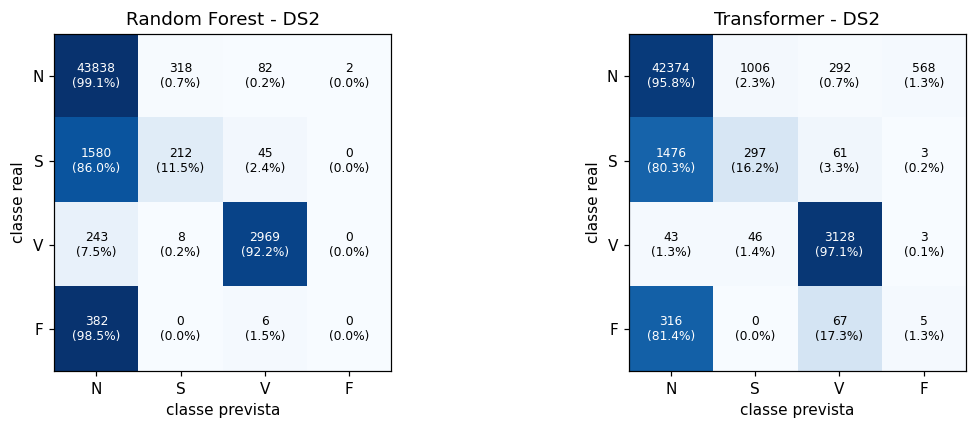

In [11]:
p_tf = principal['prob'].argmax(1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nome, p) in zip(ax, [('Random Forest', p_rf), ('Transformer', p_tf)]):
    cm = confusion_matrix(y2, p, labels=range(4))
    cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            a.text(j, i, f'{cm[i, j]}\n({100 * cmn[i, j]:.1f}%)', ha='center', va='center', fontsize=8,
                   color='white' if cmn[i, j] > 0.6 else 'black')
    a.set_xticks(range(4), eu.CLASSES); a.set_yticks(range(4), eu.CLASSES); a.grid(False)
    a.set_xlabel('classe prevista'); a.set_ylabel('classe real'); a.set_title(f'{nome} - DS2')
plt.tight_layout(); plt.savefig(RES / 'matrizes_confusao.png', bbox_inches='tight'); plt.show()

### Comparação com a literatura no mesmo protocolo

de Chazal, O'Dwyer e Reilly (2004), que propuseram a divisão DS1/DS2, reportam no DS2 Se = 75,9% e
VPP = 38,5% para S, e Se = 77,7% e VPP = 81,9% para V, com um classificador linear sobre atributos
de morfologia e de intervalo extraídos de duas derivações. Usamos apenas a derivação MLII.

In [12]:
r0 = df_tf.iloc[0]
comp = pd.DataFrame({
    'de Chazal et al. (2004)': [75.9, 38.5, 77.7, 81.9],
    'Random Forest (nosso)': [100 * res_rf[k] for k in ['Se_S', 'VPP_S', 'Se_V', 'VPP_V']],
    'Transformer, média 5 sementes': [100 * df_tf[k].mean() for k in ['Se_S', 'VPP_S', 'Se_V', 'VPP_V']],
}, index=['Se S (%)', 'VPP S (%)', 'Se V (%)', 'VPP V (%)']).round(1)
comp

,de Chazal et al. (2004),Random Forest (nosso),"Transformer, média 5 sementes"
Se S (%),75.9,11.5,20.4
VPP S (%),38.5,39.4,31.8
Se V (%),77.7,92.2,94.8
VPP V (%),81.9,95.7,86.6


## 6. Análise de erros por paciente

In [13]:
linhas = []
for r in eu.DS2:
    k = o2 == r
    lin = {'registro': r, 'n': k.sum(), 'acerto_%': 100 * (p_tf[k] == y2[k]).mean()}
    for i, c in enumerate(eu.CLASSES):
        n = ((y2 == i) & k).sum()
        lin[f'{c}'] = n
        lin[f'Se_{c}_%'] = 100 * ((p_tf == i) & (y2 == i) & k).sum() / n if n >= 10 else np.nan
    lin['falsos_pos_N'] = ((y2 == 0) & (p_tf != 0) & k).sum()
    linhas.append(lin)
df_reg = pd.DataFrame(linhas).set_index('registro').round(1)
df_reg.to_csv(RES / 'desempenho_por_registro.csv')
df_reg.sort_values('acerto_%')

,n,acerto_%,N,Se_N_%,S,Se_S_%,V,Se_V_%,F,Se_F_%,falsos_pos_N
registro,,,,,,,,,,,
232,1780,22.9,398,100.0,1382,0.7,0,NaN,0,NaN,0
222,2481,61.4,2272,60.6,209,69.9,0,NaN,0,NaN,895
219,2154,76.5,2082,75.8,7,NaN,64,98.4,1,NaN,503
213,3250,87.8,2640,99.8,28,0.0,220,97.3,362,0.6,4
105,2567,94.8,2526,95.1,0,NaN,41,75.6,0,NaN,124
210,2648,95.5,2421,96.8,22,4.5,195,93.8,10,10.0,78
202,2135,95.9,2060,96.5,55,74.5,19,94.7,1,NaN,72
123,1517,96.0,1514,96.0,0,NaN,3,NaN,0,NaN,60
200,2600,96.9,1742,98.9,30,53.3,826,94.6,2,NaN,20


In [14]:
# Métricas com e sem o registro 232, que tem 75% dos batimentos S do DS2
k = o2 != '232'
sem232 = pd.DataFrame([metricas(y2, p_tf), metricas(y2[k], p_tf[k])],
                      index=['DS2 completo', 'DS2 sem o registro 232'])
sem232[['f1_macro', 'acuracia', 'Se_S', 'VPP_S', 'F1_S', 'Se_V', 'VPP_V']].round(3)

,f1_macro,acuracia,Se_S,VPP_S,F1_S,Se_V,VPP_V
DS2 completo,0.520,0.922,0.162,0.220,0.186,0.971,0.882
DS2 sem o registro 232,0.557,0.948,0.631,0.214,0.320,0.971,0.883


In [15]:
# Para onde vão os batimentos S do registro 232
k = (o2 == '232') & (y2 == 1)
print('S do 232 classificados como:', dict(zip(eu.CLASSES, np.bincount(p_tf[k], minlength=4))))
print('RR anterior normalizado mediano dos S do 232:', np.median(R2[k, 0]).round(2))

S do 232 classificados como: {'N': np.int64(1368), 'S': np.int64(10), 'V': np.int64(4), 'F': np.int64(0)}
RR anterior normalizado mediano dos S do 232: 0.99


## 7. Protocolo intra-paciente: por que ele engana

Boa parte dos trabalhos com MIT-BIH sorteia batimentos de todos os pacientes para treino e teste. O
mesmo paciente aparece dos dois lados, e o modelo pode acertar só por reconhecer a pessoa. Para
medir o efeito, repetimos o treino do modelo completo (semente 0) com uma divisão aleatória 80/20
estratificada sobre os batimentos dos 44 registros, o mesmo tipo de split usado na Parte 2.

In [16]:
Xa = np.concatenate([X1, X2]); Ra = np.concatenate([R1, R2]); ya = np.concatenate([y1, y2])
idx_tr, idx_te = train_test_split(np.arange(len(ya)), test_size=0.2, stratify=ya, random_state=0)
idx_tr2, idx_va2 = train_test_split(idx_tr, test_size=0.15, stratify=ya[idx_tr], random_state=42)
df_intra, _ = rodar([0], 'Transformer intra-paciente',
                    dados_treino=(Xa[idx_tr2], Ra[idx_tr2], ya[idx_tr2]),
                    dados_valid=(Xa[idx_va2], Ra[idx_va2], ya[idx_va2]),
                    dados_teste=(Xa[idx_te], Ra[idx_te], ya[idx_te]))
pd.concat([df_tf.iloc[[0]], df_intra])[['config', 'acuracia', 'f1_macro', 'Se_S', 'Se_V', 'Se_F']].round(3)

C:\Users\jonny\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Transformer intra-paciente   semente 0: F1-macro=0.931  acurácia=0.991  (75 s)


,config,acuracia,f1_macro,Se_S,Se_V,Se_F
0,Transformer (completo),0.922,0.520,0.162,0.971,0.013
0,Transformer intra-paciente,0.991,0.931,0.944,0.990,0.856


## 8. Para onde o modelo olha: mapas de atenção

A atenção do token `[CLS]` na última camada indica quanto cada trecho do batimento contribuiu para
a representação usada na classificação. Não é uma explicação causal completa (a atenção é uma das
várias formas de inspecionar um Transformer, e tem limitações conhecidas), mas permite checar se o
modelo olha para regiões com sentido clínico, como o QRS e a onda P.

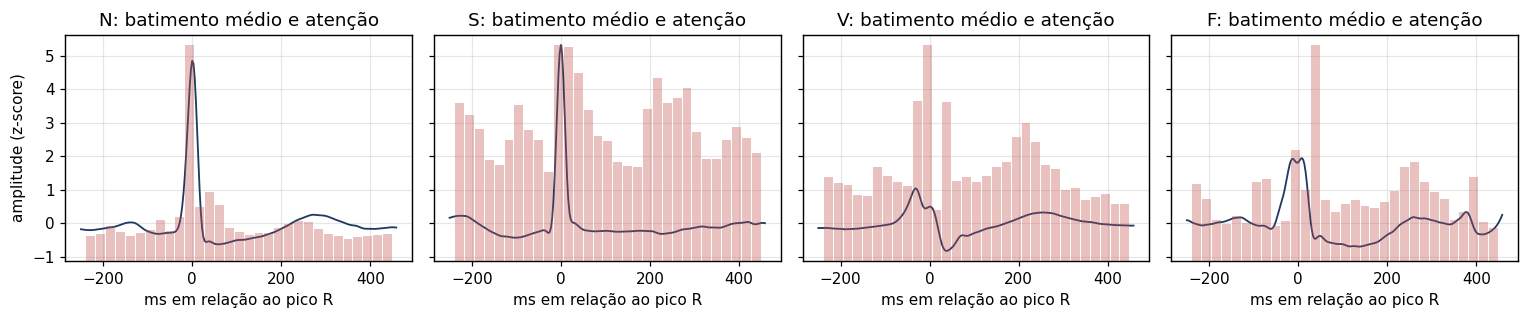

In [17]:
mod = principal['modelo'].eval()
t = (np.arange(eu.TAM_JANELA) - eu.JANELA_ANTES) / eu.FS * 1000
centros = (np.arange(31) * 8 + 8 - eu.JANELA_ANTES) / eu.FS * 1000
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for i, c in enumerate(eu.CLASSES):
    corretos = np.where((y2 == i) & (p_tf == i))[0]
    sel = rng.choice(corretos, size=min(200, len(corretos)), replace=False)
    att = mod.atencao_cls(torch.from_numpy(X2[sel]).to(DISP)).cpu().numpy().mean(0)
    ax[i].plot(t, X2[sel, 0].mean(0), color='#1f3b63', lw=1.2)
    a2 = ax[i].twinx(); a2.grid(False)
    a2.bar(centros, att, width=20, color='#c0504d', alpha=0.35)
    a2.set_yticks([])
    ax[i].set_title(f'{c}: batimento médio e atenção'); ax[i].set_xlabel('ms em relação ao pico R')
ax[0].set_ylabel('amplitude (z-score)')
plt.tight_layout(); plt.savefig(RES / 'mapas_atencao.png', bbox_inches='tight'); plt.show()

In [18]:
# Salva as métricas de todos os experimentos
todos = pd.concat([df_abl, df_intra])
todos.loc[len(todos)] = {**res_rf, 'config': 'Random Forest (baseline)', 'semente': 42}
todos.to_csv(RES / 'metricas_experimentos.csv', index=False)
resumo_tf.to_csv(RES / 'metricas_transformer_5sementes.csv')
comp.to_csv(RES / 'comparacao_literatura.csv')
tab_abl.to_csv(RES / 'tabela_ablacoes.csv')
print('arquivos em', RES.resolve())

arquivos em C:\Users\jonny\Downloads\7semestre\ia\projeto\resultados


## 9. Discussão dos resultados

**Desempenho geral.** No DS2, com pacientes que o modelo nunca viu, o Transformer chegou a F1-macro
de 0,533 ± 0,017 e acurácia de 0,929 ± 0,011 (média de 5 sementes). A classe V é a mais bem
resolvida: sensibilidade de 94,8% e VPP de 86,6%, acima dos 77,7% e 81,9% de de Chazal et al. (2004)
no mesmo protocolo. A classe S fica bem abaixo da referência (Se de 20,4% contra 75,9%), e F
praticamente não é reconhecida (F1 de 0,015).

**Transformer contra Random Forest.** O baseline teve F1-macro de 0,522, dentro de um desvio padrão
do Transformer, e acurácia maior (0,946), porque erra menos batimentos N. O Transformer encontra
quase o dobro dos S (20,4% contra 11,5%) e um pouco mais de V (94,8% contra 92,2%), ao custo de mais
falsos positivos. Com estes dados, não dá para afirmar que o Transformer é melhor que o Random Forest.
O que as ablações mostram é que o ganho veio principalmente da representação dos dados.

**Ablações.** Tirar o canal relativo ao paciente derruba o F1-macro de 0,533 para 0,452 e o VPP de V
de 86,6% para 54,5%: sem saber como é o batimento normal daquela pessoa, o modelo confunde bloqueio
de ramo com ventricular. Tirar os atributos RR derruba a sensibilidade de S de 20,4% para 10,4%,
o que confirma que o S é identificado sobretudo pelo ritmo. O peso de classe na perda ajuda S (20,4%
contra 11,9%) e custa um pouco de acurácia.

**Erros por paciente.** Quatro registros explicam a maior parte dos erros:
- **232:** 1.368 dos 1.382 batimentos S viram N. Os S são o ritmo dominante desse paciente, a
  normalização do RR pela mediana do registro apaga a prematuridade e o molde mediano passa a ser
  o próprio S. Sem esse registro, a sensibilidade de S do modelo da semente 0 sobe de 16,2% para
  63,1%, e o F1-macro de 0,520 para 0,557.
- **222 e 219:** concentram cerca de 1.400 falsos positivos (N marcados como S ou V). São pacientes
  com trechos de fibrilação e flutter atrial, em que o ritmo é irregular por natureza e os atributos
  RR deixam de indicar prematuridade.
- **213:** 362 dos 388 batimentos F do teste estão aqui, e quase todos viram N ou V. O modelo aprendeu
  F praticamente com um paciente só (208) e não generalizou para outro.

**Intra-paciente.** O mesmo modelo, treinado e testado com batimentos sorteados de todos os
pacientes, chegou a 99,1% de acurácia e F1-macro de 0,931, com 85,6% de sensibilidade em F. A
diferença para o 0,52 do protocolo inter-paciente é o tamanho do vazamento: reconhecer um paciente
já visto é muito mais fácil que generalizar para um novo. A curva de treino mostra o mesmo efeito,
com F1-macro de validação (intra-paciente) perto de 0,94 enquanto o teste fica em 0,52. Por isso
os resultados de trabalhos que usam divisão aleatória não são comparáveis com os nossos.

**Atenção.** Para batimentos N, a atenção do `[CLS]` se concentra no complexo QRS. Para S, ela se
espalha pela região da onda P (de -250 a -50 ms) e pela onda T, regiões em que o batimento
supraventricular difere do normal. Para V, ela fica no QRS alargado e na repolarização. O padrão é
coerente com a fisiologia, mas a atenção não é uma explicação completa da decisão.